In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset manzili
data_path = 'sport_inshootlari.csv'

# Datasetni o'qish
df = pd.read_csv(data_path, encoding='utf-8')

# Datasetning statistik tavsifi
df.describe(include="all")


,T/r,Hudud,Tuman(shahar),Tashkilot,Sport inshoati turi,Bino nomi
count,1497.00000,1497,1497,1497,1497,1497
unique,NaN,14,202,306,16,770
top,NaN,Farg'ona viloyati,Andijon sh.,Sportning o‘yin turlari va yengil atletika bo‘...,Спорт зали,Sport zal
freq,NaN,214,62,88,601,72
mean,749.00000,NaN,NaN,NaN,NaN,NaN
std,432.29099,NaN,NaN,NaN,NaN,NaN
min,1.00000,NaN,NaN,NaN,NaN,NaN
25%,375.00000,NaN,NaN,NaN,NaN,NaN
50%,749.00000,NaN,NaN,NaN,NaN,NaN
75%,1123.00000,NaN,NaN,NaN,NaN,NaN


In [4]:
# 1. GroupBy yordamida guruhlash

group_result = (
    df.groupby(['Hudud', 'Tuman(shahar)', 'Sport inshoati turi'])
      .agg(
          Inshootlar_soni=('T/r', 'count'),
          Tashkilotlar_soni=('Tashkilot', 'nunique'),
          Binolar_soni=('Bino nomi', 'nunique')
      )
      .reset_index()
)

print(group_result)

                Hudud Tuman(shahar) Sport inshoati turi  Inshootlar_soni  \
0    Andijon viloyati       Andijon      Futbol maydoni                1   
1    Andijon viloyati       Andijon          Спорт зали                1   
2    Andijon viloyati   Andijon sh.   Basketbol maydoni                3   
3    Andijon viloyati   Andijon sh.    Baydarka ellingi                1   
4    Andijon viloyati   Andijon sh.      Futbol maydoni                6   
..                ...           ...                 ...              ...   
700   Xorazm viloyati         Xonqa          Спорт зали                2   
701   Xorazm viloyati     Yangiariq      Futbol maydoni                2   
702   Xorazm viloyati     Yangiariq          Спорт зали                1   
703   Xorazm viloyati    Yangibozor      Futbol maydoni                2   
704   Xorazm viloyati    Yangibozor          Спорт зали                1   

     Tashkilotlar_soni  Binolar_soni  
0                    1             1  
1        

In [5]:
# Dastlabki 5 ta qator.
print(group_result.head())

# Indeks nomlari.
print(group_result.index.names)

# Barcha ustun nomlari.
print(group_result.columns)

              Hudud Tuman(shahar) Sport inshoati turi  Inshootlar_soni  \
0  Andijon viloyati       Andijon      Futbol maydoni                1   
1  Andijon viloyati       Andijon          Спорт зали                1   
2  Andijon viloyati   Andijon sh.   Basketbol maydoni                3   
3  Andijon viloyati   Andijon sh.    Baydarka ellingi                1   
4  Andijon viloyati   Andijon sh.      Futbol maydoni                6   

   Tashkilotlar_soni  Binolar_soni  
0                  1             1  
1                  1             1  
2                  2             2  
3                  1             1  
4                  3             5  
[None]
Index(['Hudud', 'Tuman(shahar)', 'Sport inshoati turi', 'Inshootlar_soni',
       'Tashkilotlar_soni', 'Binolar_soni'],
      dtype='object')


In [6]:
# Eng ko‘p sport inshootiga ega tumanlarni aniqlash

top_districts = (
    df.groupby('Tuman(shahar)')
      .size()
      .reset_index(name='Inshootlar_soni')
      .sort_values(by='Inshootlar_soni', ascending=False)
)

print(top_districts)

        Tuman(shahar)  Inshootlar_soni
2         Andijon sh.               62
26      Buxoro shahri               43
90       Nukus shahar               41
41    Farg'ona shahar               40
171        Urganch sh               28
..                ...              ...
104           Oqoltin                1
97   Ohangaron tumani                1
147          Sherobod                1
165       Tuproqqal’a                1
195         Yunusobod                1

[202 rows x 2 columns]


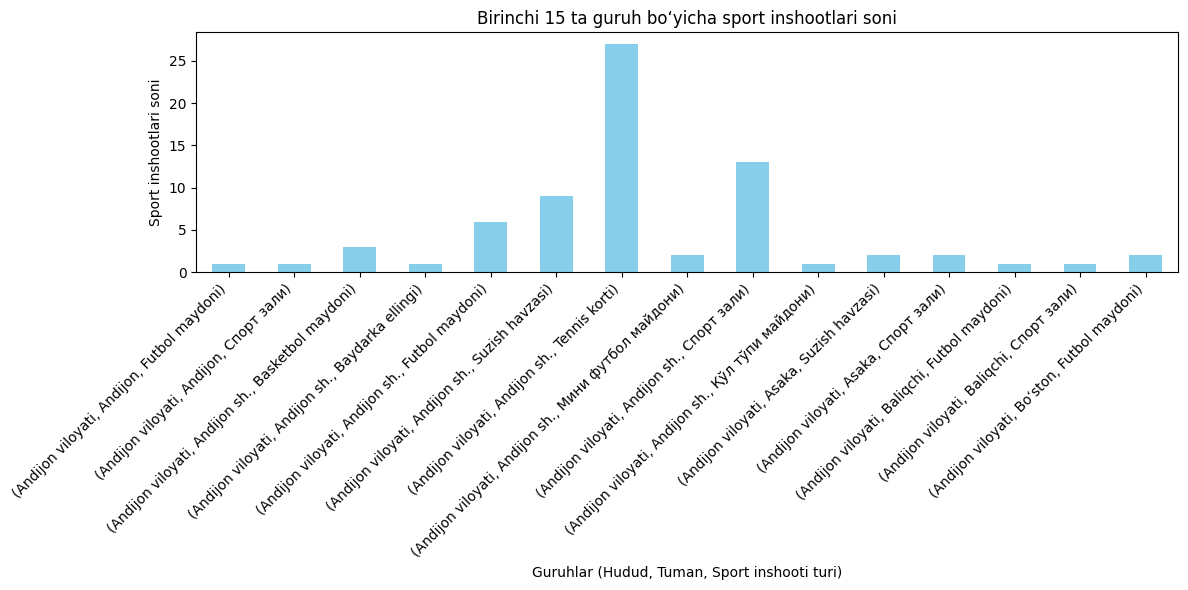

In [7]:
# 1.1. Guruhlar bo'yicha sport inshootlari sonini ajratib olish
inshoot_data = group_result.set_index(
    ['Hudud', 'Tuman(shahar)', 'Sport inshoati turi']
)['Inshootlar_soni']

# Birinchi 15 ta guruhni grafikda ko'rsatish
inshoot_data.head(15).plot(
    kind='bar',
    figsize=(12, 6),
    color='skyblue'
)

plt.title('Birinchi 15 ta guruh bo‘yicha sport inshootlari soni')
plt.xlabel('Guruhlar (Hudud, Tuman, Sport inshooti turi)')
plt.ylabel('Sport inshootlari soni')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

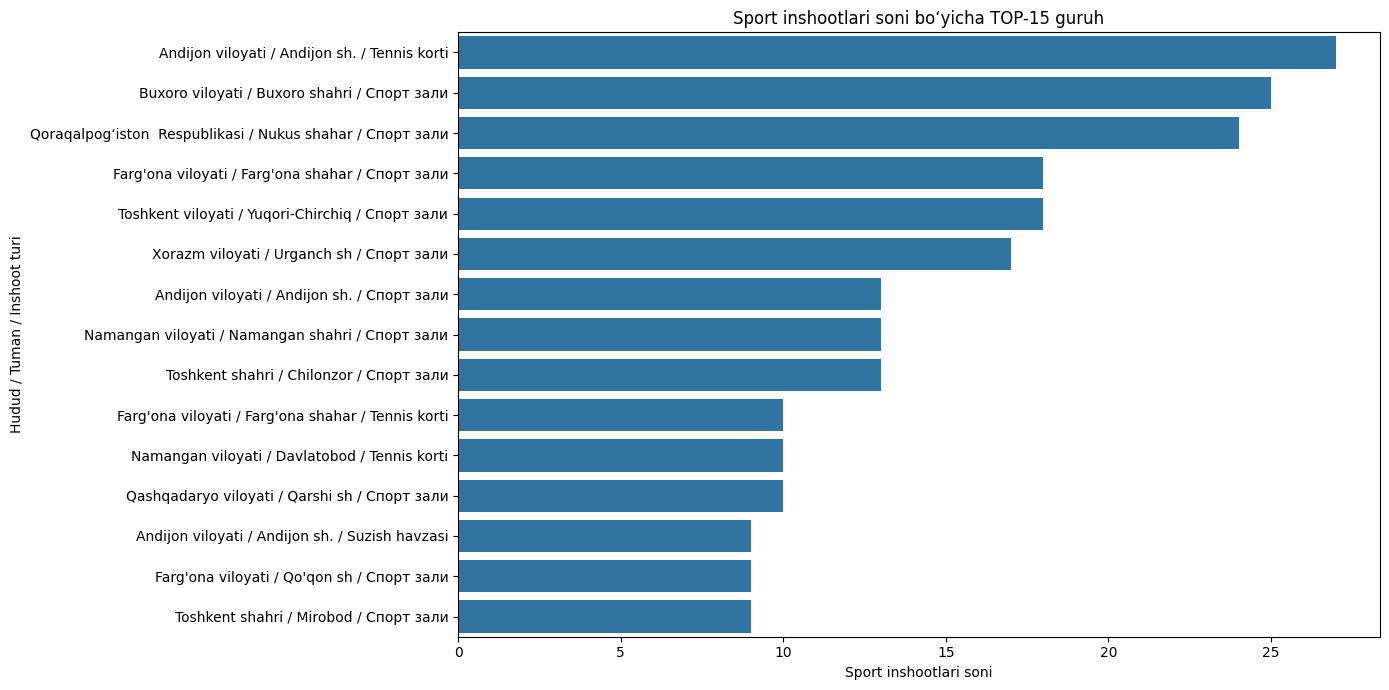

In [8]:
# Eng ko'p sport inshootlariga ega 15 ta guruh

top_15 = group_result.nlargest(15, 'Inshootlar_soni').copy()

# Grafik uchun guruh nomlarini shakllantirish
top_15['Guruh'] = (
    top_15['Hudud'] + ' / ' +
    top_15['Tuman(shahar)'] + ' / ' +
    top_15['Sport inshoati turi']
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=top_15,
    x='Inshootlar_soni',
    y='Guruh'
)

plt.title('Sport inshootlari soni bo‘yicha TOP-15 guruh')
plt.xlabel('Sport inshootlari soni')
plt.ylabel('Hudud / Tuman / Inshoot turi')
plt.tight_layout()
plt.show()

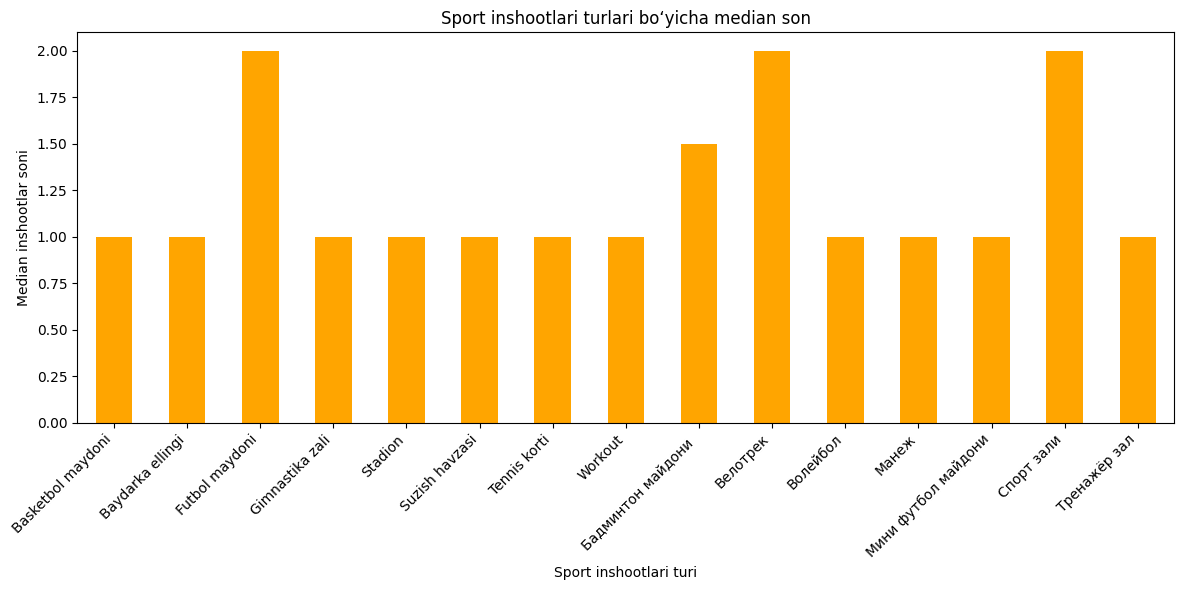

In [9]:
# Har bir sport inshooti turi bo'yicha median qiymat

median_data = (
    group_result.groupby('Sport inshoati turi')['Inshootlar_soni']
    .median()
)

# Birinchi 15 ta guruhni grafikda ko'rsatish
median_data.head(15).plot(
    kind='bar',
    figsize=(12, 6),
    color='orange'
)

plt.title('Sport inshootlari turlari bo‘yicha median son')
plt.xlabel('Sport inshootlari turi')
plt.ylabel('Median inshootlar soni')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [10]:
# 2. Pivot jadval yaratish

pivot_table = pd.pivot_table(
    df,
    values='T/r',
    index='Hudud',
    columns='Sport inshoati turi',
    aggfunc='count',
    fill_value=0
)

print(pivot_table)

Sport inshoati turi             Basketbol maydoni  Baydarka ellingi  \
Hudud                                                                 
Andijon viloyati                                4                 1   
Buxoro viloyati                                 5                 1   
Farg'ona viloyati                              16                 1   
Jizzax viloyati                                 7                 0   
Namangan viloyati                               5                 0   
Navoiy viloyati                                 0                 0   
Qashqadaryo viloyati                           11                 0   
Qoraqalpog‘iston  Respublikasi                  9                 0   
Samarqand viloyati                              2                 0   
Sirdaryo viloyati                               7                 0   
Surxondaryo viloyati                            2                 0   
Toshkent shahri                                 5                 0   
Toshke

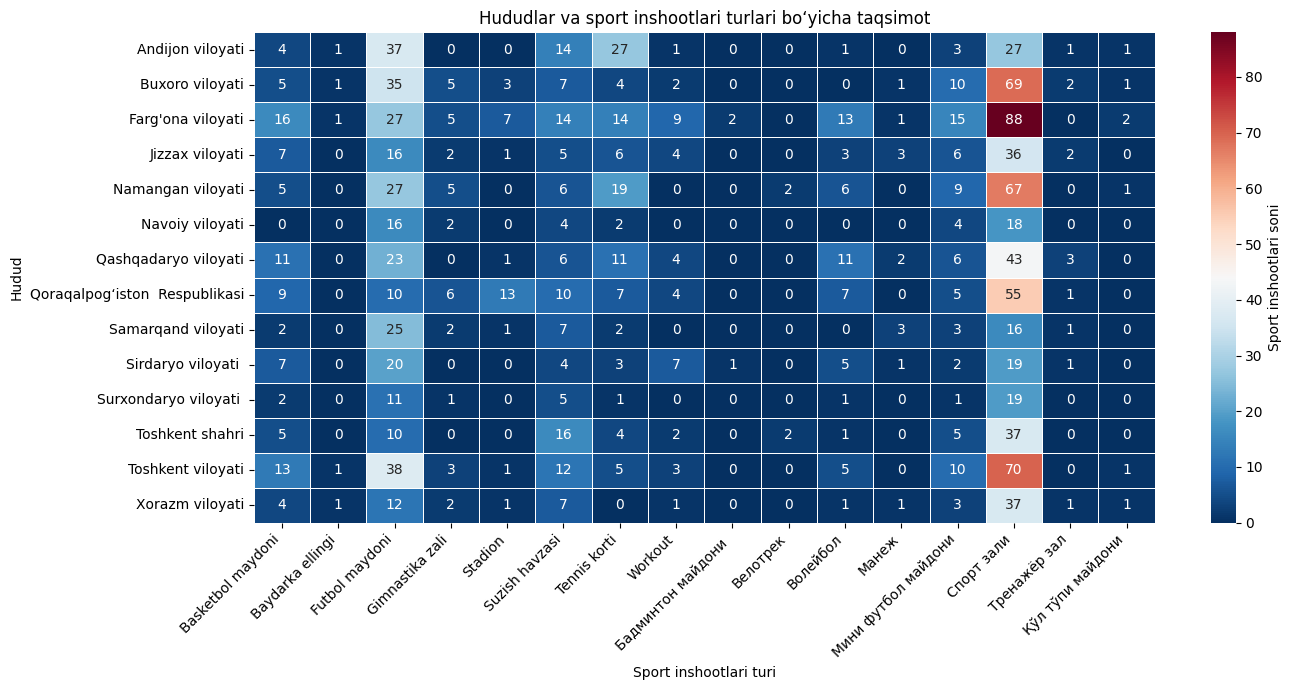

In [11]:
# 3. Pivot jadvalni Heatmap yordamida vizualizatsiya qilish

plt.figure(figsize=(14, 7))

sns.heatmap(
    pivot_table.head(15),
    annot=True,
    fmt='.0f',
    cmap='RdBu_r',
    linewidths=0.5,
    cbar_kws={'label': 'Sport inshootlari soni'}
)

plt.title('Hududlar va sport inshootlari turlari bo‘yicha taqsimot')
plt.xlabel('Sport inshootlari turi')
plt.ylabel('Hudud')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [12]:
# 4. Sport inshootlari ulushini hisoblash

pivot_target = pd.crosstab(
    df['Hudud'],
    df['Sport inshoati turi'],
    normalize='index'
) * 100

# Natijani chiqarish
print(pivot_target.round(2))

Sport inshoati turi             Basketbol maydoni  Baydarka ellingi  \
Hudud                                                                 
Andijon viloyati                             3.42              0.85   
Buxoro viloyati                              3.45              0.69   
Farg'ona viloyati                            7.48              0.47   
Jizzax viloyati                              7.69              0.00   
Namangan viloyati                            3.40              0.00   
Navoiy viloyati                              0.00              0.00   
Qashqadaryo viloyati                         9.09              0.00   
Qoraqalpog‘iston  Respublikasi               7.09              0.00   
Samarqand viloyati                           3.23              0.00   
Sirdaryo viloyati                           10.00              0.00   
Surxondaryo viloyati                         4.88              0.00   
Toshkent shahri                              6.10              0.00   
Toshke

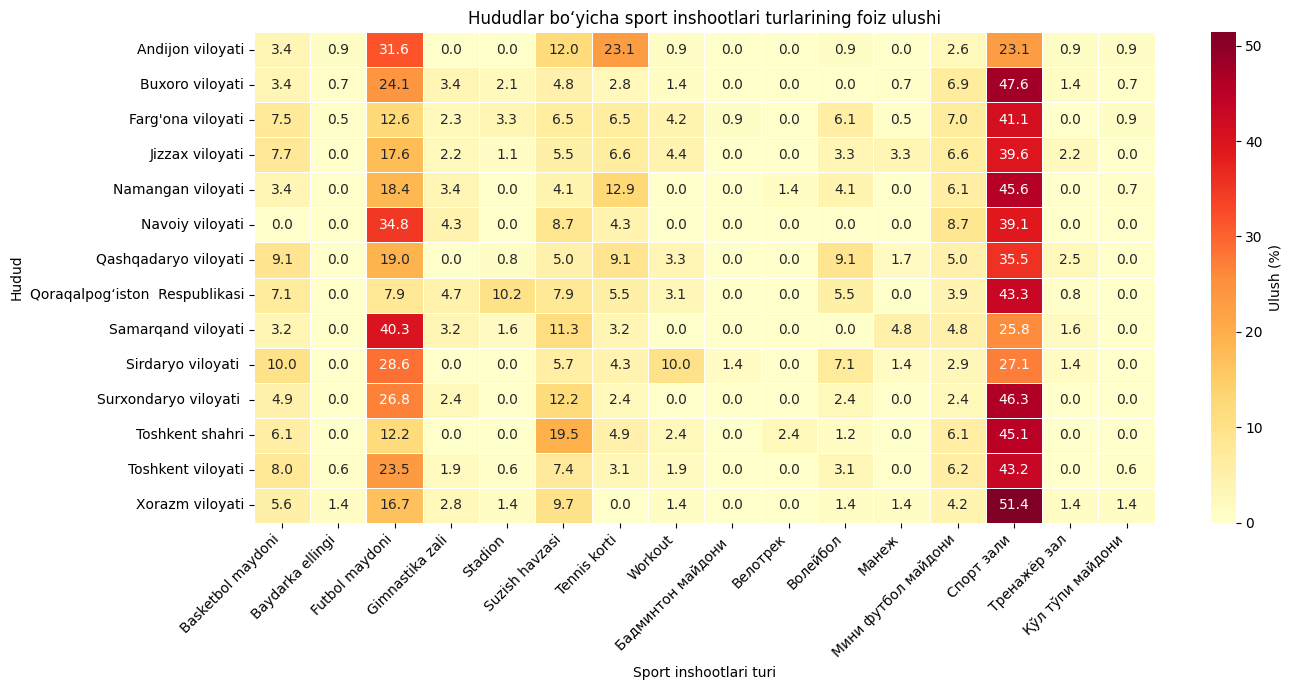

In [13]:
# 4.1. Heatmap yordamida vizualizatsiya

plt.figure(figsize=(14, 7))

sns.heatmap(
    pivot_target.head(15),
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Ulush (%)'}
)

plt.title('Hududlar bo‘yicha sport inshootlari turlarining foiz ulushi')
plt.xlabel('Sport inshootlari turi')
plt.ylabel('Hudud')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [14]:
# 5. Sonli ustunlarni aniqlash

numeric_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Sonli o‘zgaruvchilar:")
print(numeric_columns)

Sonli o‘zgaruvchilar:
Index(['T/r'], dtype='object')


In [15]:
# 5.1. Kategorik ustunlarni aniqlash

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print("Kategorik o‘zgaruvchilar:")
print(categorical_columns)

Kategorik o‘zgaruvchilar:
Index(['Hudud', 'Tuman(shahar)', 'Tashkilot', 'Sport inshoati turi',
       'Bino nomi'],
      dtype='object')


In [16]:
# Har bir kategorik ustundagi noyob qiymatlar soni

for col in categorical_columns:
    print(f"\n{col}:")
    print("Noyob qiymatlar soni:", df[col].nunique())


Hudud:
Noyob qiymatlar soni: 14

Tuman(shahar):
Noyob qiymatlar soni: 202

Tashkilot:
Noyob qiymatlar soni: 306

Sport inshoati turi:
Noyob qiymatlar soni: 16

Bino nomi:
Noyob qiymatlar soni: 770


In [17]:
# Har bir ustundagi TOP-10 qiymat

for col in categorical_columns:
    print(f"\n{col} bo‘yicha TOP-10:")
    print(df[col].value_counts().head(10))


Hudud bo‘yicha TOP-10:
Hudud
Farg'ona viloyati                 214
Toshkent viloyati                 162
Namangan viloyati                 147
Buxoro viloyati                   145
Qoraqalpog‘iston  Respublikasi    127
Qashqadaryo viloyati              121
Andijon viloyati                  117
Jizzax viloyati                    91
Toshkent shahri                    82
Xorazm viloyati                    72
Name: count, dtype: int64

Tuman(shahar) bo‘yicha TOP-10:
Tuman(shahar)
Andijon sh.        62
Buxoro shahri      43
Nukus shahar       41
Farg'ona shahar    40
Urganch sh         28
Davlatobod         25
Yuqori-Chirchiq    25
Qarshi sh          25
Namangan shahri    22
Mirobod            20
Name: count, dtype: int64

Tashkilot bo‘yicha TOP-10:
Tashkilot
Sportning o‘yin turlari va yengil atletika bo‘yicha ixtisoslashtirilgan sport maktabi    88
Suv sport turlariga ixtisoslashtirilgan sport maktabi                                    33
Sportning yakka kurash turlariga ixtisoslashtirilg

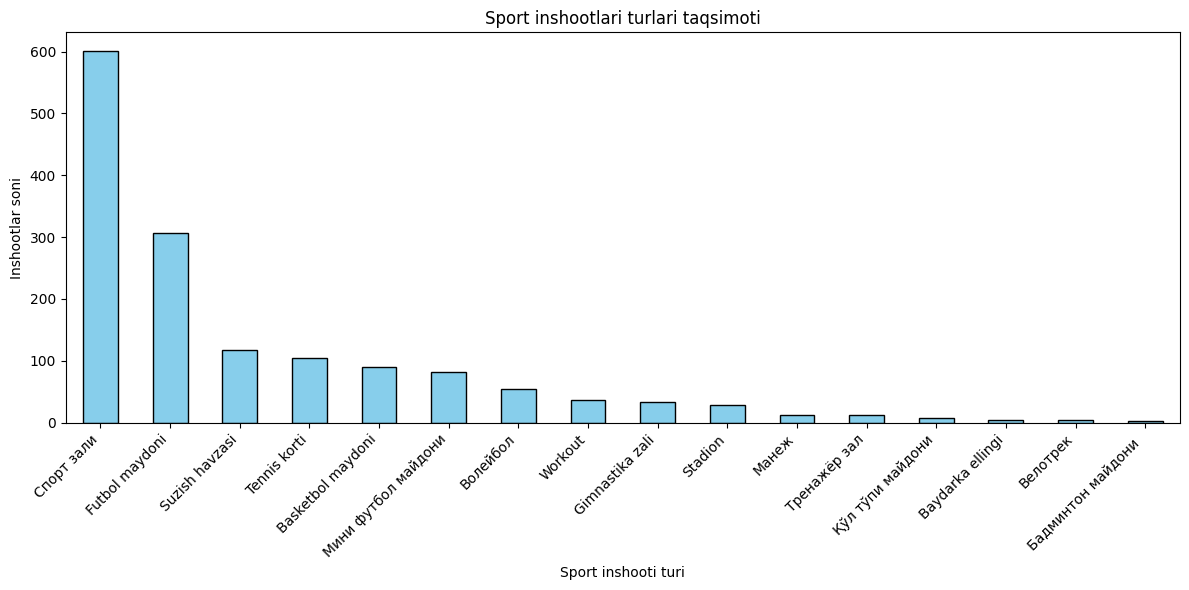

In [18]:
# 5.2. O‘zgaruvchilarni grafikda taqqoslash

# Sport inshootlari turlari bo'yicha taqsimot
df['Sport inshoati turi'].value_counts().plot(
    kind='bar',
    figsize=(12, 6),
    color='skyblue',
    edgecolor='black'
)

plt.title('Sport inshootlari turlari taqsimoti')
plt.xlabel('Sport inshooti turi')
plt.ylabel('Inshootlar soni')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

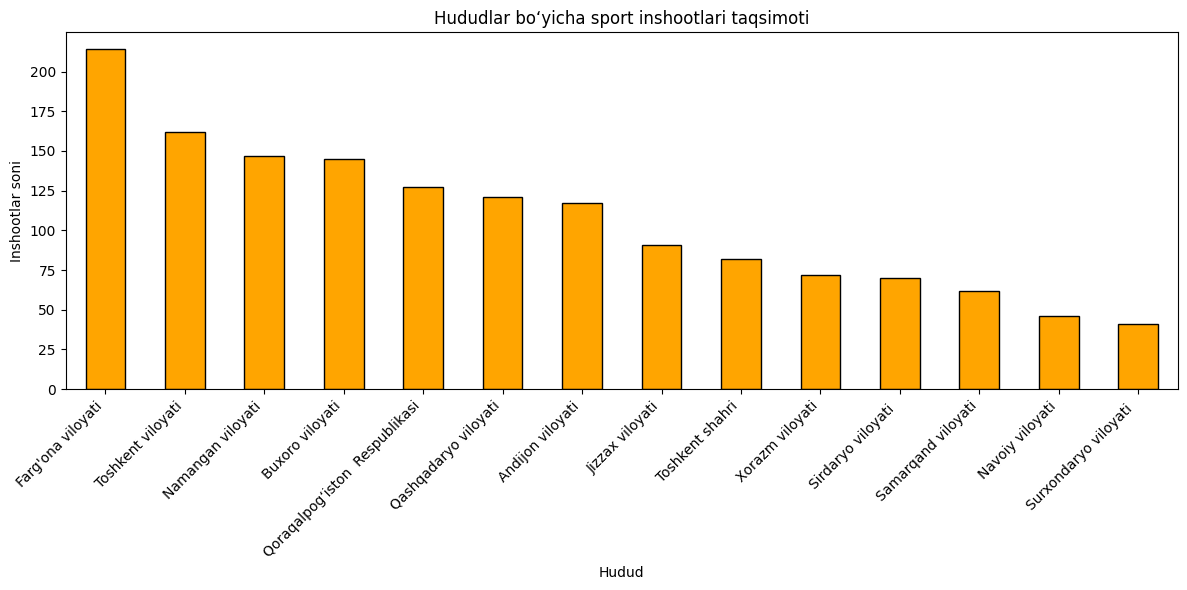

In [19]:
# Hududlar bo‘yicha sport inshootlari taqsimoti
df['Hudud'].value_counts().plot(
    kind='bar',
    figsize=(12, 6),
    color='orange',
    edgecolor='black'
)

plt.title('Hududlar bo‘yicha sport inshootlari taqsimoti')
plt.xlabel('Hudud')
plt.ylabel('Inshootlar soni')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

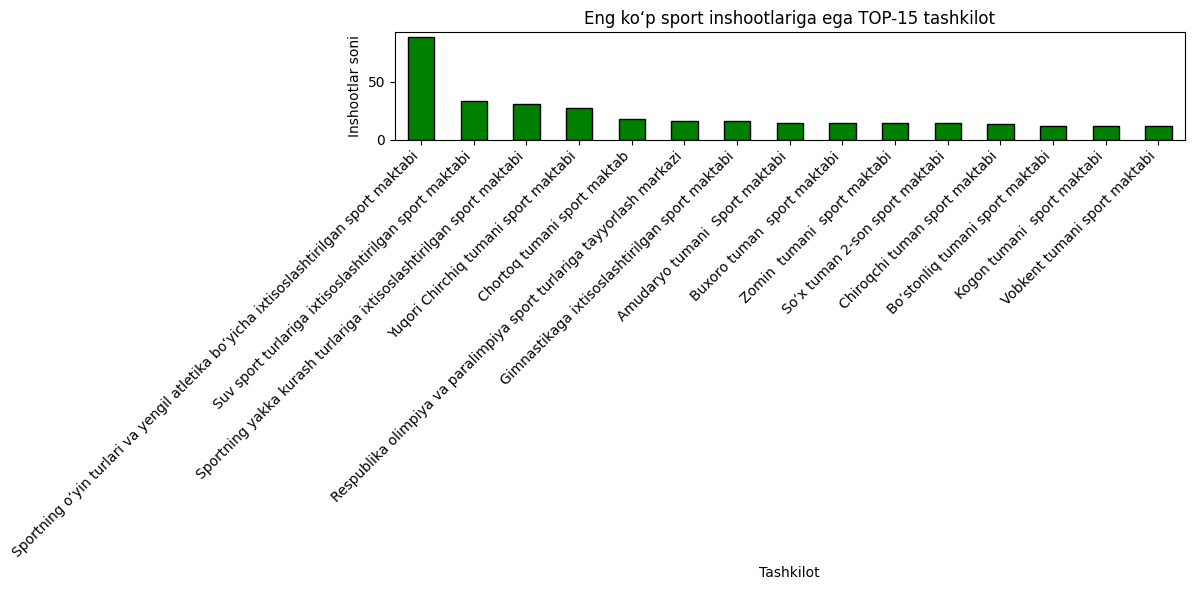

In [20]:
# Tashkilotlar bo‘yicha taqsimot
df['Tashkilot'].value_counts().head(15).plot(
    kind='bar',
    figsize=(12, 6),
    color='green',
    edgecolor='black'
)

plt.title('Eng ko‘p sport inshootlariga ega TOP-15 tashkilot')
plt.xlabel('Tashkilot')
plt.ylabel('Inshootlar soni')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

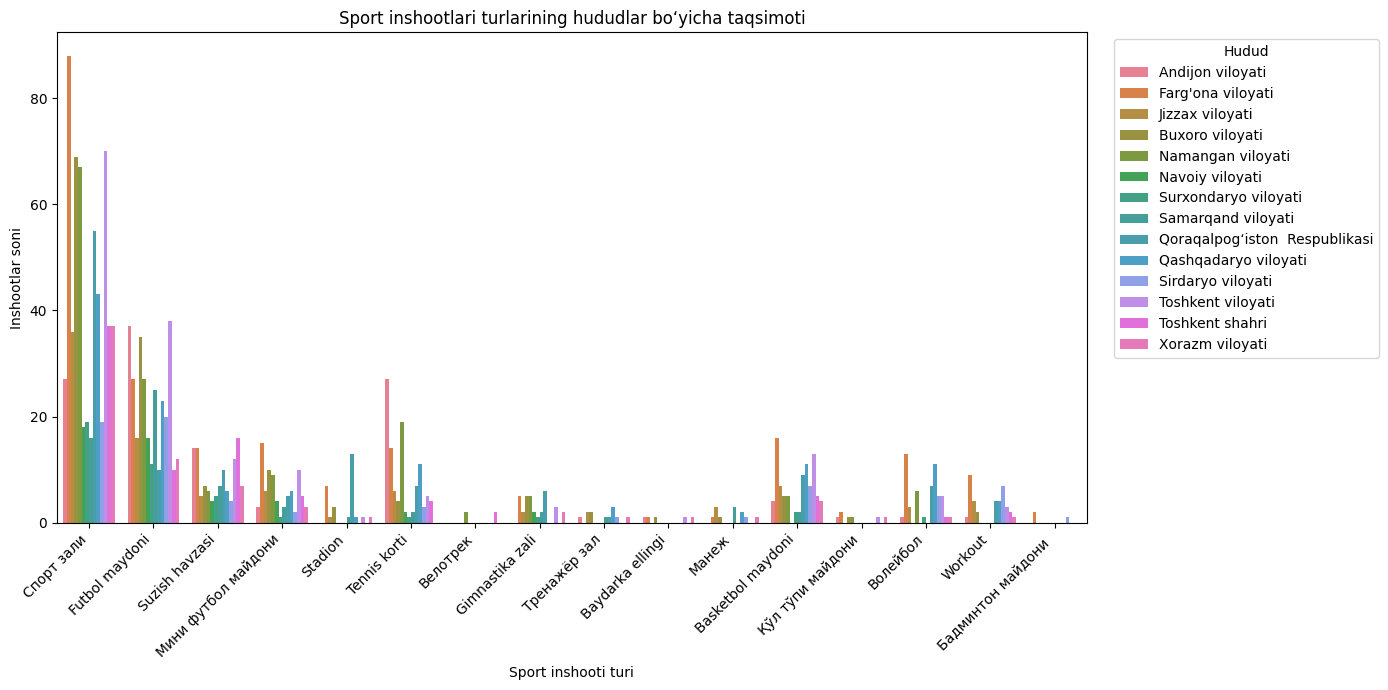

In [21]:
# 5.3. Kategorik o‘zgaruvchilar

# Sport inshootlari turlarini hududlar kesimida taqqoslash
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    x='Sport inshoati turi',
    hue='Hudud'
)

plt.title('Sport inshootlari turlarining hududlar bo‘yicha taqsimoti')
plt.xlabel('Sport inshooti turi')
plt.ylabel('Inshootlar soni')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Hudud', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [22]:
# 6. Korrelatsiya

# Cramér's V korrelatsiya - kategorik ustunlar o‘rtasidagi statistik bog‘liqlik kuchini aniqlaydi. Natija 0 dan 1 gacha bo‘ladi.

from scipy.stats import chi2_contingency

# Kategorik ustunlarni ajratish
categorical_df = df.select_dtypes(include=['object', 'category'])

# Cramér's V funksiyasi
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape

    return np.sqrt(chi2 / (n * min(k - 1, r - 1)))

# Korrelatsiya matritsasini yaratish
columns = categorical_df.columns
cramers_matrix = pd.DataFrame(
    index=columns,
    columns=columns,
    dtype=float
)

for col1 in columns:
    for col2 in columns:
        cramers_matrix.loc[col1, col2] = cramers_v(
            categorical_df[col1],
            categorical_df[col2]
        )

print(cramers_matrix.round(2))

                     Hudud  Tuman(shahar)  Tashkilot  Sport inshoati turi  \
Hudud                 1.00           1.00       0.95                 0.15   
Tuman(shahar)         1.00           1.00       0.98                 0.38   
Tashkilot             0.95           0.98       1.00                 0.49   
Sport inshoati turi   0.15           0.38       0.49                 1.00   
Bino nomi             0.79           0.75       0.75                 0.94   

                     Bino nomi  
Hudud                     0.79  
Tuman(shahar)             0.75  
Tashkilot                 0.75  
Sport inshoati turi       0.94  
Bino nomi                 1.00  


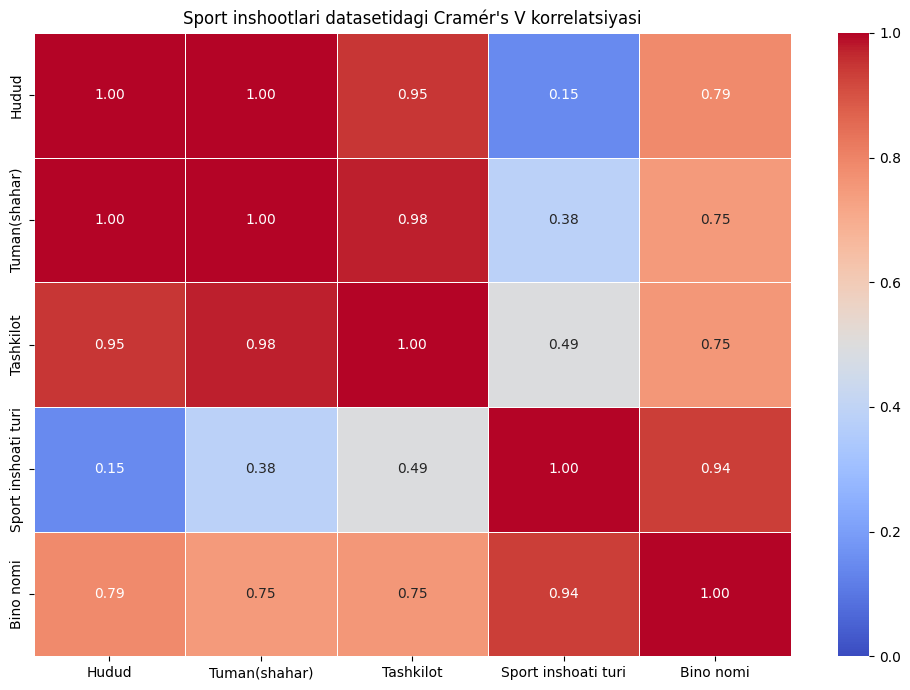

In [23]:
# 6.1. Heatmap yordamida korrelatsiyani ko‘rsatish

plt.figure(figsize=(10, 7))

sns.heatmap(
    cramers_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Sport inshootlari datasetidagi Cramér's V korrelatsiyasi")
plt.tight_layout()
plt.show()

In [24]:
# 7. Outliersni aniqlash

# Outliers aniqlash uchun ustunlar
columns = ['Inshootlar_soni', 'Tashkilotlar_soni', 'Binolar_soni']

outlier_result = {}

for col in columns:
    Q1 = group_result[col].quantile(0.25)
    Q3 = group_result[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = group_result[
        (group_result[col] < lower) |
        (group_result[col] > upper)
    ]

    outlier_result[col] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower': lower,
        'Upper': upper,
        'Outliers count': len(outliers)
    }

outlier_df = pd.DataFrame(outlier_result).T

print(outlier_df.round(2))

                    Q1   Q3  IQR  Lower  Upper  Outliers count
Inshootlar_soni    1.0  2.0  1.0   -0.5    3.5            84.0
Tashkilotlar_soni  1.0  1.0  0.0    1.0    1.0           112.0
Binolar_soni       1.0  2.0  1.0   -0.5    3.5            56.0


In [25]:
# Outliers mavjud hudud va tumanlarni chiqarish

Q1 = group_result['Inshootlar_soni'].quantile(0.25)
Q3 = group_result['Inshootlar_soni'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = group_result[
    (group_result['Inshootlar_soni'] < lower) |
    (group_result['Inshootlar_soni'] > upper)
]

print(outliers[
    ['Hudud', 'Tuman(shahar)',
     'Sport inshoati turi', 'Inshootlar_soni']
])

                 Hudud    Tuman(shahar) Sport inshoati turi  Inshootlar_soni
4     Andijon viloyati      Andijon sh.      Futbol maydoni                6
5     Andijon viloyati      Andijon sh.      Suzish havzasi                9
6     Andijon viloyati      Andijon sh.        Tennis korti               27
8     Andijon viloyati      Andijon sh.          Спорт зали               13
16    Andijon viloyati       Buloqboshi      Futbol maydoni                5
..                 ...              ...                 ...              ...
662  Toshkent viloyati  Yuqori-Chirchiq      Futbol maydoni                4
664  Toshkent viloyati  Yuqori-Chirchiq          Спорт зали               18
675    Xorazm viloyati  Hazorasp tumani          Спорт зали                6
690    Xorazm viloyati       Urganch sh      Suzish havzasi                4
692    Xorazm viloyati       Urganch sh          Спорт зали               17

[84 rows x 4 columns]


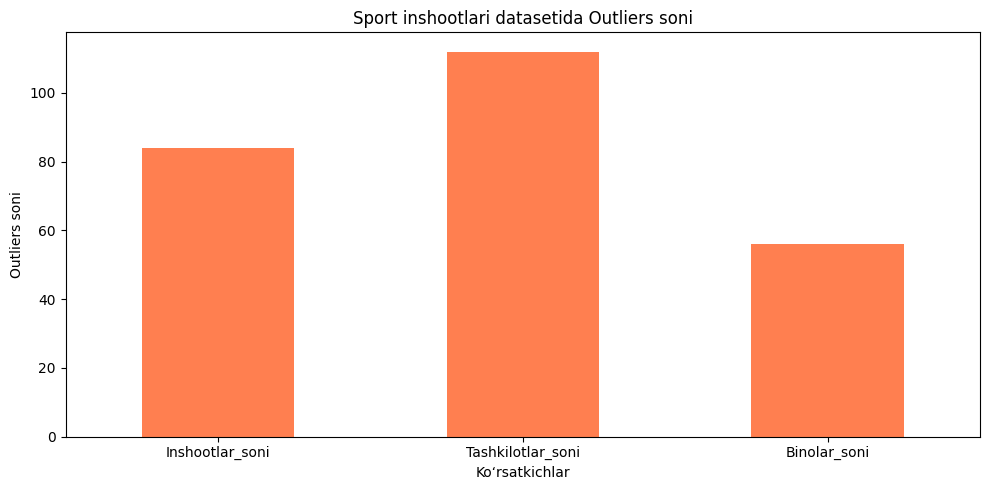

In [26]:
# Outliers sonini diagrammada ko‘rsatish

outlier_df['Outliers count'].plot(
    kind='bar',
    figsize=(10, 5),
    color='coral'
)

plt.title('Sport inshootlari datasetida Outliers soni')
plt.xlabel('Ko‘rsatkichlar')
plt.ylabel('Outliers soni')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

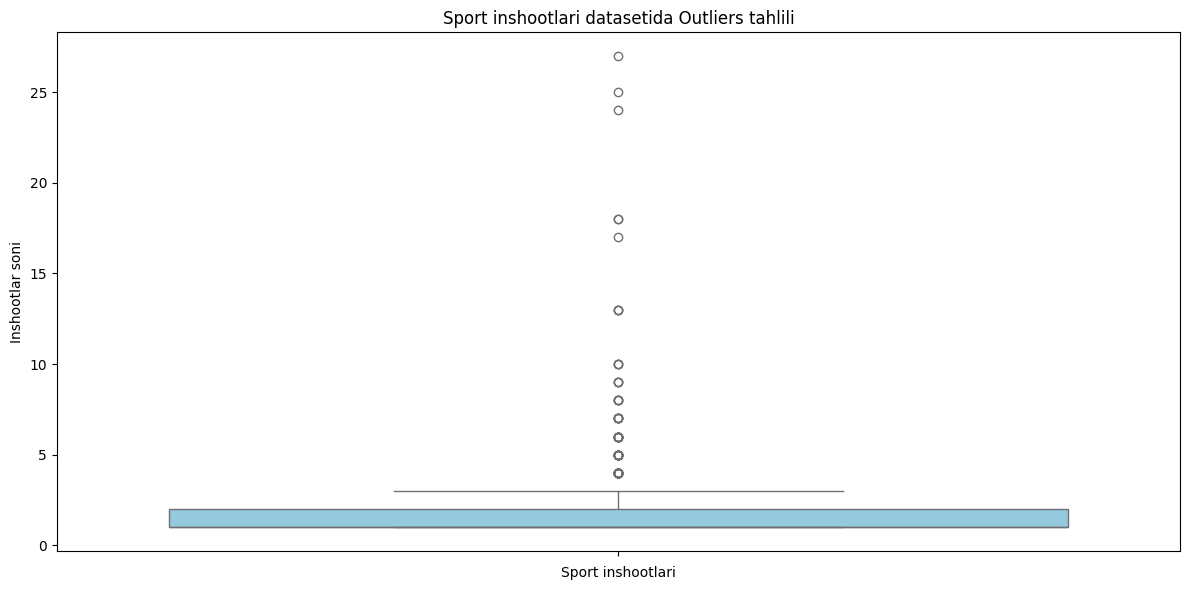

In [27]:
# 8. Boxplot yordamida Outliersni ko‘rish

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=group_result,
    y='Inshootlar_soni',
    color='skyblue'
)

plt.title('Sport inshootlari datasetida Outliers tahlili')
plt.xlabel('Sport inshootlari')
plt.ylabel('Inshootlar soni')

plt.tight_layout()
plt.show()